In [ ]:
# This notebook lives in project/early_stage_notebooks/; every path below is relative to project/
import os

if os.path.basename(os.getcwd()) == "early_stage_notebooks":
    os.chdir("..")

# The cloud fund – Group 4

**20598 – Finance with Big Data.** Can a normal investor use the paper's idea without satellites?

* In `Replication_Group4.ipynb` we find what the paper finds: when clouds hide the storage hubs, the EIA
  report is news, and the oil price reacts more.
* In `Satellite_Group4.ipynb` our free Sentinel 2 index tracks the level of Cushing stocks, but not the weekly
  changes. So copying a satellite fund gives us no edge.
* Here we try what a normal investor can do: read the free cloud data, and buy a USO straddle (a call and a put)
  before the EIA report in cloudy weeks only. If cloudy weeks bring bigger moves, the straddle should pay
  more in those weeks.
* Verdict: does it beat always buying the straddle, and in which periods?

The data are in `data/raw/`. Release dates, inventory surprises and cloudy weeks are built exactly as in
`Replication_Group4.ipynb`; we copy its functions here and do not change that notebook.

## 0. Setup
Libraries, the chart theme and the helpers of `Replication_Group4.ipynb`. Run from the `project/` folder.

In [1]:
import functools
import os
import re
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pandas.tseries.holiday import USFederalHolidayCalendar

pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# Chart theme of Replication_Group4.ipynb (inspired by The Economist)
ECONOMIST_RED = "#E3120B"
BLUE, CYAN, TEAL, YELLOW = "#006BA2", "#3EBCD2", "#379A8B", "#EBB434"
PURPLE, LIGHT_RED = "#9A607F", "#DB444B"
DARK, GREY, LIGHT_GREY = "#333333", "#758D99", "#C9D3D9"
ECONOMIST_COLORS = [BLUE, CYAN, TEAL, YELLOW, "#B4BA39", PURPLE, "#D1B07C", GREY, LIGHT_RED]
GRID = "#D0D0D0"
CLEAR, CLOUDY, ALWAYS = YELLOW, BLUE, GREY  # yellow = clear weeks, blue = cloudy weeks, grey = every week

plt.rcParams.update({
    "figure.figsize": (14, 5.5),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=ECONOMIST_COLORS),
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": GRID,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "ytick.left": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})


def show(title=None):
    '''Add the headline, the red rule and the tag on top of the current figure, then display it.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout()
    fig.add_artist(plt.Line2D([0, 1], [1.02, 1.02], transform=fig.transFigure, color=ECONOMIST_RED, lw=1.5))
    fig.add_artist(plt.Rectangle((0, 1.02), 0.035, 0.015, transform=fig.transFigure, color=ECONOMIST_RED,
                                 clip_on=False))
    plt.show()


def annotate(ax, text, xy, offset=(9, 0), **kwargs):
    '''Write `text` next to the point xy, shifted by `offset` points; other arguments go to ax.annotate.'''
    dx = offset[0]
    style = {"ha": "left" if dx > 0 else "right" if dx < 0 else "center", "va": "center", "fontsize": 9.5,
             "color": DARK}
    ax.annotate(text, xy, xytext=offset, textcoords="offset points", **{**style, **kwargs})


def minus_sign(text):
    '''Write a true minus sign in front of numbers.'''
    return re.sub(r"-(?=\d)", "−", text)


SIGNED = FuncFormatter(lambda value, _: minus_sign(f"{value:+.1f}"))  # axis of signed values in %

## 1. Data
### 1.1 Release dates and inventory surprises (copied from `Replication_Group4.ipynb`)

In [3]:
RAW = os.path.join("data", "raw")
SOURCES = {  # local file: public URL, no login needed (both files are already in data/raw)
    "eia_WCESTUS1w.xls": "https://www.eia.gov/dnav/pet/hist_xls/WCESTUS1w.xls",  # crude stocks excluding SPR
    "eia_wpsr_archive.html": "https://www.eia.gov/petroleum/supply/weekly/archive/",  # release dates
}


def fetch(name):
    '''Local path of a public source file; downloads it on the first call only.'''
    path = os.path.join(RAW, name)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        request = urllib.request.Request(SOURCES[name], headers={"User-Agent": "fbd-replication"})
        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()
        with open(path, "wb") as file:
            file.write(content)
    return path


def read_eia(name):
    '''An EIA history file (sheet "Data 1") as a dated series.'''
    table = pd.read_excel(fetch(name), sheet_name="Data 1", skiprows=2)
    return table.set_index(table.columns[0]).iloc[:, 0].rename_axis("date").astype(float)


stocks = read_eia("eia_WCESTUS1w.xls") / 1000  # million barrels
with open(fetch("eia_wpsr_archive.html"), encoding="utf-8") as file:
    archive_html = file.read()

In [4]:
EXPECTATION_WEEKS = 4  # expected change = mean change of the previous four reports (paper, Section 4.2)


def archive_dates(html):
    '''Release dates of the Weekly Petroleum Status Report listed in EIA's archive.'''
    return pd.to_datetime(sorted(set(re.findall(r"archive/\d{4}/(\d{4}_\d{2}_\d{2})/", html))), format="%Y_%m_%d")


def rule_dates(first, last):
    '''The paper's release rule, plus Friday when Christmas or New Year fall on a Tuesday or Wednesday.'''
    holidays = USFederalHolidayCalendar().holidays(first, pd.Timestamp(last) + pd.Timedelta(days=7))
    dates = []
    for wednesday in pd.date_range(first, last, freq="W-WED"):
        week = holidays[(holidays >= wednesday - pd.Timedelta(days=2)) & (holidays <= wednesday)]
        year_end = any((day.month, day.day) in [(12, 25), (1, 1)] and day.dayofweek in (1, 2) for day in week)
        dates.append(wednesday + pd.Timedelta(days=2 if year_end else 1 if len(week) else 0))
    return pd.DatetimeIndex(dates)


def inventory_surprises(release_dates, weeks=EXPECTATION_WEEKS):
    '''One row per report: its inventory date (the last Friday at least five days before), stocks and surprise (%).'''
    reports = pd.DataFrame({"release": release_dates})
    back = (reports["release"].dt.dayofweek - 4) % 7  # days back to the previous Friday...
    back = back.where(back >= 5, back + 7)  # ...at least five: Wednesday -5, Thursday -6, Friday -7
    reports["inventory_date"] = reports["release"] - pd.to_timedelta(back, unit="D")
    reports["stocks"] = reports["inventory_date"].map(stocks)
    reports = reports.dropna(subset=["stocks"]).reset_index(drop=True)
    change = 100 * reports["stocks"].pct_change()
    reports["surprise"] = change - change.shift(1).rolling(weeks).mean()
    return reports


archive = archive_dates(archive_html)
checked = archive[archive <= "2025-12-31"]
misses = checked.difference(rule_dates(checked.min(), "2025-12-31"))
assert len(misses) <= 0.01 * len(checked)  # the rule is right for at least 99% of the archive's dates
release_dates = rule_dates("2006-06-01", archive.min() - pd.Timedelta(days=1)).union(archive)
reports = inventory_surprises(release_dates)
assert reports["inventory_date"].is_unique
print(f"{len(reports):,} reports from {reports['release'].min():%d %b %Y} to {reports['release'].max():%d %b %Y}")

1,067 reports from 07 Jun 2006 to 25 Nov 2026


### 1.2 USO one-minute bars (copied from `Replication_Group4.ipynb`)
The bars are LSEG's USO.P, the same data as the replication's `data/lseg/USO_1min.csv.gz`; here we read
`data/raw/USOP.csv.gz`. Timestamps are in GMT, and we convert them to New York time. The price at a clock
time is the last trade **before** it. A bar is stamped with its first minute, so the 10:30 bar already holds
the report's first trades; the price "at 10:30" is the close of the 10:29 bar, the last bar that ends by
10:30. A day without such a price drops out. Prices are not split adjusted, which does not matter within one
day.

In [5]:
USO_FILE = os.path.join(RAW, "USOP.csv.gz")  # LSEG one-minute bars of USO.P (licensed)
OPEN, CLOSE = 9 * 60 + 30, 16 * 60  # NYSE Arca regular hours, in minutes after midnight, New York time
MAIN_WINDOW = ("10:30", "11:00")  # the paper's main window (Table 2, first column)

bars = pd.read_csv(USO_FILE, usecols=["Date-Time", "Open", "Last"])
bars.index = pd.DatetimeIndex(pd.to_datetime(bars.pop("Date-Time"), utc=True)).tz_convert("America/New_York").tz_localize(None)
bars["minute"] = bars.index.hour * 60 + bars.index.minute  # a bar is stamped with its first minute
bars = bars[(bars["minute"] >= OPEN) & (bars["minute"] < CLOSE)].copy()
bars["day"] = bars.index.normalize()


@functools.cache
def prices_at(clock):
    '''USO's price on every trading day at clock time "hh:mm": the last trade before it; at 9:30 the opening trade.'''
    minute = int(clock[:2]) * 60 + int(clock[3:])
    if minute == OPEN:
        return bars.groupby("day")["Open"].first()
    return bars.loc[bars["minute"] < minute].groupby("day")["Last"].last()


def window_returns(start, end):
    '''Log returns (%) of USO from clock time start to end, on every trading day.'''
    return 100 * np.log(prices_at(end) / prices_at(start))


reports["ret"] = reports["release"].map(window_returns(*MAIN_WINDOW))
print(f"USO: {bars['day'].nunique():,} trading days from {bars.index.min():%d %b %Y} to {bars.index.max():%d %b %Y}; "
      f"{reports['ret'].notna().sum():,} reports with a 10:30–11:00 return")

USO: 5,006 trading days from 03 Jan 2007 to 24 Nov 2026; 1,036 reports with a 10:30–11:00 return


### 1.3 Cloudy weeks (copied from `Replication_Group4.ipynb`)
A week is cloudy if even its **least cloudy day**, from the Thursday before the inventory date to the day
before the release, lies above the 75th percentile of the sample. As in the replication, the threshold is set
within each period.

In [6]:
CLOUD_FILE = os.path.join("data", "out", "hourly_cover_long.csv.gz")  # local hour x hub, from 04_build_long_sample.py
DAYLIGHT = (7, 18)  # local hours averaged into a day (paper, Table 1)
MIN_HOUR_SHARE = 0.5  # a hub's day counts only with sky readings for at least half of these hours
CLOUDY_QUANTILE = 0.75  # cloudy week: least cloudy day above this quantile of the sample (paper, Section 4.2)

hourly_cover = pd.read_csv(CLOUD_FILE, index_col=0, parse_dates=True)


def daily_cloudiness(hours=DAYLIGHT):
    '''Mean over the ten hubs of each hub's average sky cover during the given local hours.'''
    daylight = hourly_cover[(hourly_cover.index.hour >= hours[0]) & (hourly_cover.index.hour < hours[1])]
    day = daylight.index.floor("D")
    enough = daylight.notna().groupby(day).sum() >= MIN_HOUR_SHARE * (hours[1] - hours[0])
    return daylight.groupby(day).mean().where(enough).mean(axis=1)


def weekly_cloudiness(daily, how="min", first_day=-1):
    '''Least cloudy day (or mean) from the day before the inventory date (first_day=-1, a Thursday)
    to the day before the release, for every report.'''
    values = []
    for inventory_date, release in zip(reports["inventory_date"], reports["release"]):
        window = daily.loc[inventory_date + pd.Timedelta(days=first_day): release - pd.Timedelta(days=1)]
        values.append(getattr(window, how)())
    return pd.Series(values, index=reports.index)


daily_cloud = daily_cloudiness()
reports["cloud_min"] = weekly_cloudiness(daily_cloud)

PERIODS = {  # sample: first and last release date
    "2007–11": ("2007-01-01", "2011-12-31"),  # pre-period, few commercial satellites (paper, Table 3)
    "2014–18": ("2014-01-01", "2018-12-31"),  # baseline (paper, Table 2)
    "2019–25": ("2019-01-01", "2025-12-31"),  # out of sample, until NOAA's weather data end (August 2025)
}


def weeks_of(period, cloud="cloud_min", surprise="surprise", quantile=CLOUDY_QUANTILE, data=None):
    '''Report weeks of a sample with the surprise scaled to unit standard deviation (x) and the cloudy dummy
    at the sample's quantile; period is a name of PERIODS or a (first, last) pair.'''
    first, last = PERIODS[period] if period in PERIODS else period
    data = reports if data is None else data
    sample = data[data["release"].between(first, last)].dropna(subset=["ret", surprise, cloud]).copy()
    sample["x"] = sample[surprise] / sample[surprise].std()
    sample["threshold"] = sample[cloud].quantile(quantile)
    sample["cloudy"] = (sample[cloud] > sample["threshold"]).astype(float)
    return sample

## 2. Our rules, fixed before we look at any result

**Mechanism check (Section 3).** For each release we take USO's log return from 10:30 to 11:00 a.m. New York
time, the paper's window. We compare the mean **absolute** move in cloudy and clear weeks, per period
(2007–11, 2014–18, 2019–25, as in the replication), with a bootstrap p-value.

**The straddle (Section 4).**
1. One trade per EIA release. Cloudy week: the **replication's label** of that week, from its own sample and
   threshold per period (2007–11, 2014–18, 2019–25; the straddle's 2019–24 uses the 2019–25 labels). A week
   the replication does not label (no 10:30–11:00 return) drops out.
2. Entry at the close of the trading day before the release, exit at the close of the release day.
3. Cost = expected one-day move = (call premium + put premium) / forward price / √21, from OptionMetrics'
   standardised 30-day at-the-money options on the entry day. 30 calendar days are about 21 trading days. For
   normal returns this is close to the mean absolute daily move (a straddle is worth about 0.8 σ √T).
4. Payoff = absolute value of USO's `return` on the release day (close to close, adjusted for the 1-for-8
   reverse split of 29 April 2020).
5. Profit = payoff − cost, in % of the USO price. This is a **simplified** straddle profit: we hold the
   straddle for one day and value it as if only the day's move mattered. We ignore the remaining time value
   and delta changes.
6. Strategies: **Always** (every release), **Cloudy only**, **Clear only**.
7. Periods: 2007–11 (placebo, few satellites), 2014–18 (the paper's baseline), 2019–24. The straddle stops in
   December 2024 because the OptionMetrics data end there, so its last period is 2019–24, not 2019–25.
   Options start on 9 May 2007, so 2007–11 starts then.
8. Per strategy and period: number of trades, mean profit, t-statistic, hit rate (share of trades with a
   profit), and Cloudy minus Always with a bootstrap p-value. We plot the cumulative profit.

**Robustness (Section 5), one change at a time.**
* Cost from implied volatility instead of premiums: mean of the call and put implied volatility / √252.
  This is the daily σ, which is about 25% above the mean absolute move, so this cost is higher.
* 10-day options instead of 30-day, from 2014 only (the 10-day rows are empty before about 2014). Cost = 10-day
  straddle / forward / √7, as 10 calendar days are about 7 trading days.
* Intraday payoff, as a sensitivity only: the absolute 10:30 to 11:00 move against the cost scaled to 30
  minutes, cost × √(30/390) (a trading day has 390 minutes). We could not trade this with daily options.

**Upper bound.** The cost has no bid-ask spread and no event premium: the real price of a straddle bought the
day before an EIA report is higher than the average day's. So all profits here are an upper bound.

**Bootstrap.** 5,000 draws of weeks with replacement within each period, seed 20598, and the two-sided
p-value of the replication (twice the share of draws on the far side of zero).

## 3. Mechanism check: are cloudy weeks' moves bigger in the paper's window?

In [7]:
BOOT_DRAWS = 5_000  # bootstrap draws behind every p-value
SEED = 20598        # every bootstrap starts from this seed, so reruns give the same numbers


def p_value(draws):
    '''Two-sided bootstrap p-value: twice the share of draws on the far side of zero.'''
    return min(1.0, 2 * min((draws <= 0).mean(), (draws >= 0).mean()))


def bootstrap_means(values, cloudy):
    '''Mean of cloudy weeks, clear weeks and all weeks in BOOT_DRAWS samples of weeks drawn with replacement.'''
    rng = np.random.default_rng(SEED)
    values, cloudy = np.asarray(values, float), np.asarray(cloudy, bool)
    rows = rng.integers(0, len(values), size=(BOOT_DRAWS, len(values)))
    v, c = values[rows], cloudy[rows]
    return {"cloudy": (v * c).sum(axis=1) / c.sum(axis=1),
            "clear": (v * ~c).sum(axis=1) / (~c).sum(axis=1),
            "all": v.mean(axis=1)}


mechanism = {}
for period in PERIODS:
    sample = weeks_of(period)  # weeks with a 10:30-11:00 return, cloudy dummy as in the replication
    move, cloudy = sample["ret"].abs(), sample["cloudy"] == 1
    draws = bootstrap_means(move, cloudy)
    mechanism[period] = {"clear weeks": (~cloudy).sum(), "cloudy weeks": cloudy.sum(),
                         "clear |move| (%)": move[~cloudy].mean(), "cloudy |move| (%)": move[cloudy].mean(),
                         "cloudy − clear": move[cloudy].mean() - move[~cloudy].mean(),
                         "p": p_value(draws["cloudy"] - draws["clear"])}
mechanism = pd.DataFrame(mechanism).T
mechanism.astype({"clear weeks": int, "cloudy weeks": int})

,clear weeks,cloudy weeks,clear |move| (%),cloudy |move| (%),cloudy − clear,p
2007–11,196,65,0.774,0.728,-0.045,0.614
2014–18,196,65,0.724,0.701,-0.023,0.818
2019–25,259,87,0.521,0.529,0.008,0.883


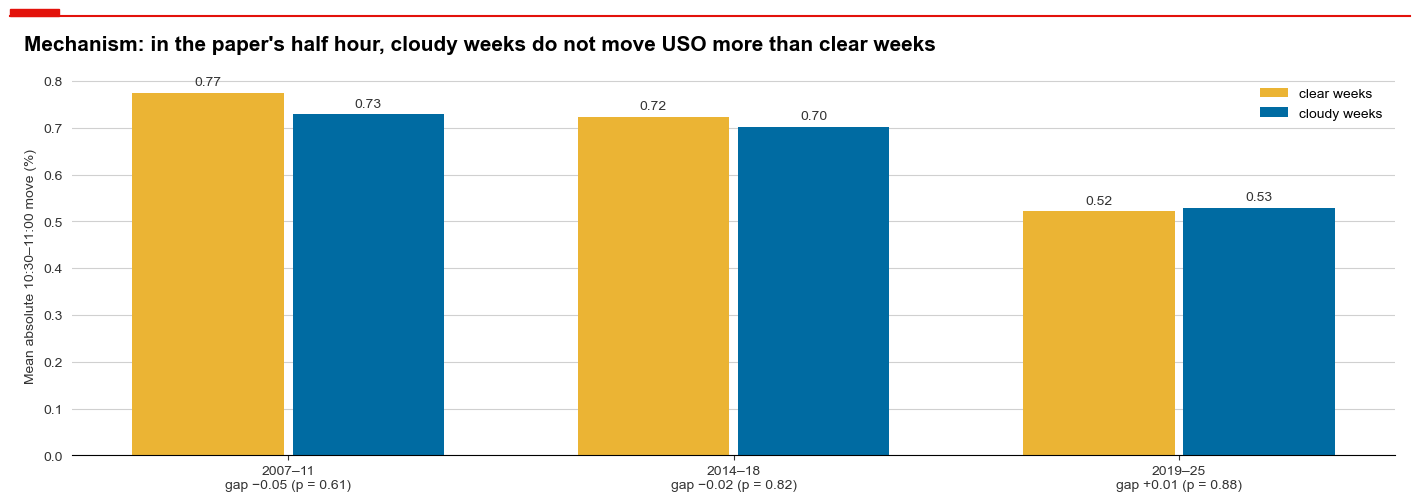

In [8]:
fig, ax = plt.subplots(figsize=(14, 4.8))
positions = np.arange(len(mechanism))
for shift, name, color in [(-0.18, "clear", CLEAR), (0.18, "cloudy", CLOUDY)]:
    values = mechanism[f"{name} |move| (%)"]
    ax.bar(positions + shift, values, width=0.34, color=color, label=f"{name} weeks")
    for x, value in zip(positions + shift, values):
        ax.text(x, value + 0.01, f"{value:.2f}", ha="center", va="bottom", fontsize=10, color=DARK)
ax.set_xticks(positions, [minus_sign(f"{period}\ngap {row['cloudy − clear']:+.2f} (p = {row['p']:.2f})")
                          for period, row in mechanism.iterrows()])
ax.set_ylabel("Mean absolute 10:30–11:00 move (%)")
ax.legend(loc="upper right")
show("Mechanism: in the paper's half hour, cloudy weeks do not move USO more than clear weeks")

## 4. The straddle

In [9]:
options = pd.read_csv(os.path.join(RAW, "optionmetrics_uso_std_30d.csv"), parse_dates=["date"])
uso = pd.read_csv(os.path.join(RAW, "optionmetrics_uso_prices.csv"), parse_dates=["date"], index_col="date")
STRADDLE_PERIODS = {"2007–11": PERIODS["2007–11"], "2014–18": PERIODS["2014–18"],
                    "2019–24": ("2019-01-01", "2024-12-31")}  # OptionMetrics ends in December 2024


def straddle_costs(days, trading_days):
    '''Expected one-day move (fraction of the price) on each date, from at-the-money options of `days` days:
    from the premiums ("cost") and from the implied volatility ("cost_iv").'''
    table = options[(options["days"] == days) & (options["premium"] > 0)]
    wide = table.pivot(index="date", columns="cp_flag", values=["premium", "forward_price", "impl_volatility"])
    straddle = (wide["premium"]["C"] + wide["premium"]["P"]) / wide["forward_price"]["C"]
    return pd.DataFrame({"cost": straddle / np.sqrt(trading_days),
                         "cost_iv": wide["impl_volatility"].mean(axis=1) / np.sqrt(252)}).dropna()


def trade_table(cost, payoff):
    '''One row per release: cost (%) on the trading day before, payoff (%) on the release day, and profit.'''
    table = reports[reports["release"].isin(uso.index)].copy()
    position = uso.index.get_indexer(table["release"])
    table, position = table[position > 0], position[position > 0]  # we need a trading day before
    table["entry"] = uso.index[position - 1]
    table["cost"] = 100 * cost.reindex(table["entry"]).to_numpy()
    table["payoff"] = payoff.reindex(table["release"]).to_numpy()
    table["profit"] = table["payoff"] - table["cost"]
    return table.dropna(subset=["cost", "payoff"])


# The replication's cloudy label of every week: its own sample and threshold per period
REPLICATION_LABELS = pd.concat([weeks_of(period)[["release", "threshold", "cloudy"]] for period in PERIODS])


def by_period(trades, periods=STRADDLE_PERIODS):
    '''Trades of each period with the replication's cloudy label of their week; unlabelled weeks drop out.'''
    labelled = trades.merge(REPLICATION_LABELS, on="release")
    return {period: labelled[labelled["release"].between(*span)] for period, span in periods.items()}


def strategy_rows(samples):
    '''Trades, mean profit, t-statistic and hit rate per strategy and period, and Cloudy minus Always.'''
    rows = {}
    for period, sample in samples.items():
        cloudy = sample["cloudy"] == 1
        draws = bootstrap_means(sample["profit"], cloudy)
        for name, chosen in {"Always": cloudy | ~cloudy, "Cloudy only": cloudy, "Clear only": ~cloudy}.items():
            profit = sample.loc[chosen, "profit"]
            rows[(period, name)] = {"trades": len(profit), "mean profit (%)": profit.mean(),
                                    "t": profit.mean() / (profit.std() / np.sqrt(len(profit))),
                                    "hit rate": (profit > 0).mean()}
        gap = rows[(period, "Cloudy only")]["mean profit (%)"] - rows[(period, "Always")]["mean profit (%)"]
        rows[(period, "Cloudy only")].update({"cloudy − always": gap,
                                              "p": p_value(draws["cloudy"] - draws["all"])})
    return pd.DataFrame(rows).T.astype({"trades": int})


costs_30 = straddle_costs(30, trading_days=21)
daily_payoff = 100 * uso["return"].abs()  # % of the price
main = by_period(trade_table(costs_30["cost"], daily_payoff))
main_table = strategy_rows(main)
main_table

trades  mean profit (%)      t  hit rate  \
2007–11 Always          242           -0.023 -0.240     0.405   
        Cloudy only      58           -0.042 -0.211     0.379   
        Clear only      184           -0.017 -0.155     0.413   
2014–18 Always          261            0.160  1.858     0.479   
        Cloudy only      65            0.479  2.502     0.508   
        Clear only      196            0.053  0.568     0.469   
2019–24 Always          311           -0.107 -1.267     0.376   
        Cloudy only      77            0.059  0.267     0.442   
        Clear only      234           -0.162 -1.896     0.355   

                     cloudy − always     p  
2007–11 Always                   NaN   NaN  
        Cloudy only           -0.019 0.898  
        Clear only               NaN   NaN  
2014–18 Always                   NaN   NaN  
        Cloudy only            0.320 0.042  
        Clear only               NaN   NaN  
2019–24 Always                   NaN   NaN  
        Cloudy only            0.167 0.361  
        Clear only               NaN   NaN

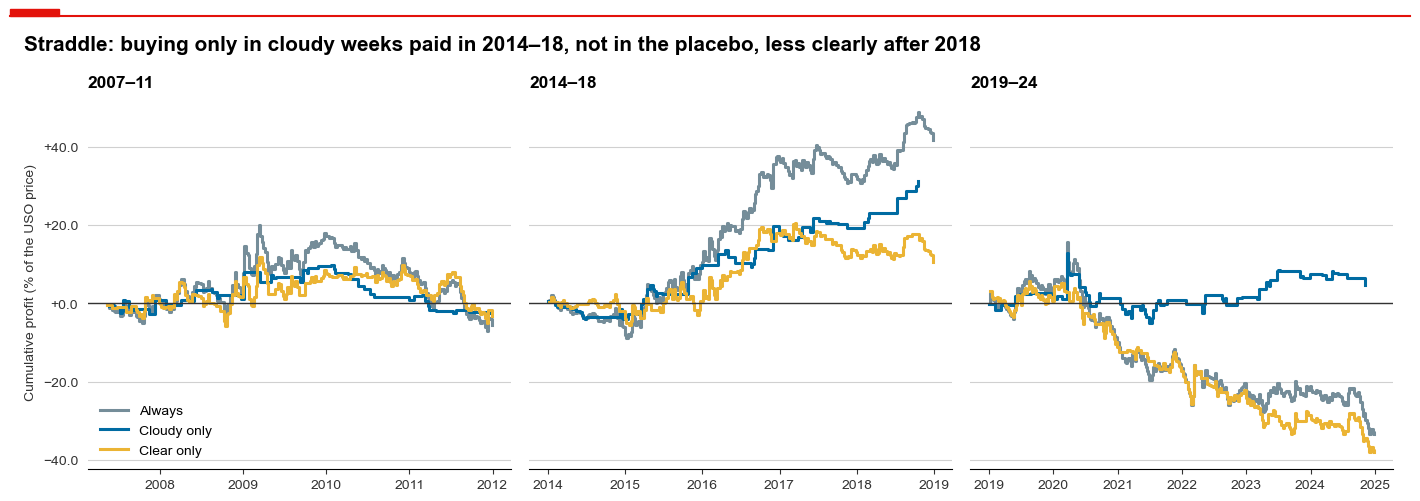

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for ax, (period, sample) in zip(axes, main.items()):
    cloudy = sample["cloudy"] == 1
    for name, chosen, color in [("Always", cloudy | ~cloudy, ALWAYS), ("Cloudy only", cloudy, CLOUDY),
                                ("Clear only", ~cloudy, CLEAR)]:
        path = sample.loc[chosen].set_index("release")["profit"].cumsum()
        ax.step(path.index, path, where="post", color=color, lw=2.2, label=name)
    ax.axhline(0, color=DARK, lw=1)
    ax.set_title(period, fontsize=12.5)
    ax.yaxis.set_major_formatter(SIGNED)
axes[0].set_ylabel("Cumulative profit (% of the USO price)")
axes[0].legend(loc="lower left")
show("Straddle: buying only in cloudy weeks paid in 2014–18, not in the placebo, less clearly after 2018")

## 5. Robustness, one change at a time

In [11]:
costs_10 = straddle_costs(10, trading_days=7)
intraday_payoff = reports.set_index("release")["ret"].abs()  # 10:30-11:00, in %
FROM_2014 = {period: span for period, span in STRADDLE_PERIODS.items() if period != "2007–11"}

robustness = {
    "Main: 30-day premiums, daily payoff": main,
    "Cost from implied volatility": by_period(trade_table(costs_30["cost_iv"], daily_payoff)),
    "10-day options (from 2014)": by_period(trade_table(costs_10["cost"], daily_payoff), FROM_2014),
    "Intraday payoff (sensitivity only)": by_period(trade_table(costs_30["cost"] * np.sqrt(30 / 390),
                                                                intraday_payoff)),
}
robustness_tables = {name: strategy_rows(samples) for name, samples in robustness.items()}

summary = {}
for name, table in robustness_tables.items():
    for period in table.index.get_level_values(0).unique():
        summary[(name, period)] = {
            "trades": table.loc[(period, "Always"), "trades"],
            "Always (%)": table.loc[(period, "Always"), "mean profit (%)"],
            "Cloudy only (%)": table.loc[(period, "Cloudy only"), "mean profit (%)"],
            "Clear only (%)": table.loc[(period, "Clear only"), "mean profit (%)"],
            "cloudy − always": table.loc[(period, "Cloudy only"), "cloudy − always"],
            "p": table.loc[(period, "Cloudy only"), "p"]}
summary = pd.DataFrame(summary).T.astype({"trades": int})
summary

trades  Always (%)  \
Main: 30-day premiums, daily payoff 2007–11     242      -0.023   
                                    2014–18     261       0.160   
                                    2019–24     311      -0.107   
Cost from implied volatility        2007–11     242      -0.551   
                                    2014–18     261      -0.266   
                                    2019–24     311      -0.608   
10-day options (from 2014)          2014–18     261       0.127   
                                    2019–24     311      -0.134   
Intraday payoff (sensitivity only)  2007–11     242       0.198   
                                    2014–18     261       0.269   
                                    2019–24     311       0.018   

                                             Cloudy only (%)  Clear only (%)  \
Main: 30-day premiums, daily payoff 2007–11           -0.042          -0.017   
                                    2014–18            0.479           0.053   
                                    2019–24            0.059          -0.162   
Cost from implied volatility        2007–11           -0.525          -0.559   
                                    2014–18            0.077          -0.380   
                                    2019–24           -0.463          -0.656   
10-day options (from 2014)          2014–18            0.458           0.017   
                                    2019–24            0.025          -0.186   
Intraday payoff (sensitivity only)  2007–11            0.168           0.207   
                                    2014–18            0.276           0.267   
                                    2019–24            0.001           0.024   

                                             cloudy − always     p  
Main: 30-day premiums, daily payoff 2007–11           -0.019 0.898  
                                    2014–18            0.320 0.042  
                                    2019–24            0.167 0.361  
Cost from implied volatility        2007–11            0.025 0.894  
                                    2014–18            0.343 0.026  
                                    2019–24            0.145 0.422  
10-day options (from 2014)          2014–18            0.331 0.033  
                                    2019–24            0.159 0.386  
Intraday payoff (sensitivity only)  2007–11           -0.029 0.671  
                                    2014–18            0.007 0.916  
                                    2019–24           -0.017 0.676

## 6. Where the 2014–18 profit comes from (diagnostic, added after seeing the results)
Not a new rule: we split the main profit into payoff and cost, and look at each year of 2014–18.

In [12]:
split = pd.concat({period: sample.groupby(sample["cloudy"].map({0: "clear", 1: "cloudy"}))[["payoff", "cost",
                                                                                               "profit"]].mean()
                   for period, sample in main.items()})
split

payoff  cost  profit
        cloudy                      
2007–11 clear    2.038 2.056  -0.017
        cloudy   1.796 1.838  -0.042
2014–18 clear    1.701 1.648   0.053
        cloudy   2.014 1.534   0.479
2019–24 clear    1.714 1.877  -0.162
        cloudy   2.041 1.981   0.059

In [13]:
baseline_trades = main["2014–18"]
year_gap = {}
for year, sample in baseline_trades.groupby(baseline_trades["release"].dt.year):
    cloudy = sample["cloudy"] == 1
    year_gap[year] = {"cloudy weeks": cloudy.sum(), "Always (%)": sample["profit"].mean(),
                      "Cloudy only (%)": sample.loc[cloudy, "profit"].mean()}
year_gap = pd.DataFrame(year_gap).T.astype({"cloudy weeks": int})
year_gap["cloudy − always"] = year_gap["Cloudy only (%)"] - year_gap["Always (%)"]
year_gap

,cloudy weeks,Always (%),Cloudy only (%),cloudy − always
2014,17,-0.152,-0.235,-0.083
2015,15,0.356,0.924,0.568
2016,12,0.501,0.718,0.217
2017,12,-0.079,0.060,0.139
2018,9,0.177,1.328,1.151


## 7. Verdict

* **The mechanism does not show up in the size of the move.** In the paper's window, 10:30 to 11:00 a.m.,
  USO moves as much in clear weeks as in cloudy weeks, in every period (gaps of −0.05 to +0.01 percentage
  points, p ≥ 0.6). The paper's result is about the *direction* of the reaction to the surprise, which a
  straddle does not use.
* **Over the whole release day, cloudy weeks paid in 2014–18.** Buying the straddle only in cloudy weeks
  earned 0.48% of the USO price per trade, against 0.16% for every week: +0.32 points, p = 0.04. Cloudy weeks
  had bigger moves (2.01% against 1.70%) and slightly cheaper options. The gap holds with the cost from
  implied volatility (+0.34, p = 0.03) and with 10-day options (+0.33, p = 0.03). It comes from 2015, 2016 and
  2018, not from one year.
* **Per trade, not in total.** In 2014–18 Cloudy only earns more per trade, but trades a quarter as often, so
  Always ends higher in total (chart in Section 4). In 2019–24 Cloudy only also wins in total, because Always
  loses money there.
* **No gain in the placebo, and a weaker one after 2018.** In 2007–11, with few satellites, Cloudy only is a
  little worse than Always (−0.02, p = 0.90). In 2019–24 it is better but not significantly (+0.17, p = 0.36).
  The pattern of the paper's story (nothing before satellites, a gain once satellites watch clear weeks) is
  there, but it is significant in only one of three periods.
* **Not in the paper's half hour.** With the intraday payoff the gap disappears (+0.01 in 2014–18, p = 0.92).
  So the extra move in cloudy weeks happens on the release day but outside 10:30 to 11:00, and the paper's
  mechanism does not explain it.
* **An upper bound.** Our cost has no bid-ask spread and no event premium, and the straddle profit is
  simplified. Real profits are lower for every strategy. An extra cost that is the same for every trade lowers
  all strategies alike and leaves the gap Cloudy minus Always unchanged.

**Risks.** One significant period out of three, after several variants, can be luck. Cloudy weeks are seasonal
(most frequent in May), so the gap can partly be a seasonal pattern in oil volatility. 58 to 77 cloudy trades per
period is a small sample, and the result depends on a few large moves.

## 8. Robustness check added after seeing results: release time

Like the replication, we measure every report from 10:30 to 11:00 a.m. But a report pushed off its Wednesday by a
holiday comes out on another day, often at another time, and then our window can miss it. Neither the
replication's code nor EIA's archive page gives release **times**, only dates, so we cannot use the 30 minutes
after each actual release. We run two versions instead.

**Rules (fixed before running):**
* **Main version: Wednesday only.** We keep the releases on a Wednesday, which we take to be at 10:30 as the
  replication does, and drop the weeks released on any other day.
* **Sensitivity: 11:00 assumed.** We keep all weeks and use 11:00 to 11:30 for the weeks released on another day.
  **11:00 is an assumption** (EIA's usual time for a report delayed by a holiday), not an observed time.
* Each week keeps the cloudy label it has in the original results, so only the window and the set of weeks
  change. In the intraday payoff the cost stays the daily cost × √(30/390); only the payoff window moves.

We rerun the mechanism check (Section 3) and the intraday payoff (Section 5) for the same periods as before.

In [14]:
off_wednesday = reports.loc[reports["release"].between("2007-01-01", "2025-12-31")
                            & (reports["release"].dt.dayofweek != 2), "release"]
print(f"{len(off_wednesday)} releases from 2007 to 2025 are not on a Wednesday "
      f"({off_wednesday.dt.day_name().value_counts().to_dict()}):")
for year, days in off_wednesday.groupby(off_wednesday.dt.year):
    print(year, ", ".join(days.dt.strftime("%a %d %b")))

145 releases from 2007 to 2025 are not on a Wednesday ({'Thursday': 131, 'Friday': 12, 'Monday': 2}):
2007 Thu 04 Jan, Thu 18 Jan, Thu 22 Feb, Thu 31 May, Thu 05 Jul, Thu 06 Sep, Thu 11 Oct, Thu 15 Nov, Fri 28 Dec
2008 Fri 04 Jan, Thu 24 Jan, Thu 21 Feb, Thu 29 May, Thu 04 Sep, Thu 16 Oct, Thu 13 Nov
2009 Thu 22 Jan, Thu 19 Feb, Thu 28 May, Thu 10 Sep, Thu 15 Oct, Thu 12 Nov
2010 Thu 21 Jan, Thu 18 Feb, Thu 03 Jun, Thu 08 Jul, Thu 09 Sep, Thu 14 Oct
2011 Thu 20 Jan, Thu 24 Feb, Thu 02 Jun, Thu 07 Jul, Thu 08 Sep, Thu 13 Oct, Thu 29 Dec
2012 Thu 05 Jan, Thu 19 Jan, Thu 23 Feb, Thu 31 May, Thu 05 Jul, Thu 06 Sep, Thu 11 Oct, Thu 01 Nov, Thu 15 Nov, Fri 28 Dec
2013 Fri 04 Jan, Thu 24 Jan, Thu 21 Feb, Thu 30 May, Thu 05 Sep, Mon 21 Oct, Thu 14 Nov, Fri 27 Dec
2014 Fri 03 Jan, Thu 23 Jan, Thu 20 Feb, Thu 29 May, Thu 04 Sep, Thu 16 Oct, Thu 13 Nov
2015 Thu 22 Jan, Thu 19 Feb, Thu 28 May, Thu 10 Sep, Thu 15 Oct, Thu 12 Nov
2016 Thu 21 Jan, Thu 18 Feb, Thu 02 Jun, Thu 07 Jul, Thu 08 Sep, Thu 1

In [15]:
late_returns = window_returns("11:00", "11:30")  # the assumed window for releases off Wednesday


def on_wednesday(sample):
    '''Only the weeks whose report came out on a Wednesday.'''
    return sample[sample["release"].dt.dayofweek == 2]


def late_move(sample):
    '''Mechanism sample with the 11:00-11:30 return for the weeks released off Wednesday.'''
    off = sample["release"].dt.dayofweek != 2
    ret = sample["ret"].where(~off, sample["release"].map(late_returns))
    return sample.assign(ret=ret).dropna(subset=["ret"])


def late_payoff(sample):
    '''Intraday payoff sample with the absolute 11:00-11:30 move for the weeks released off Wednesday.'''
    off = sample["release"].dt.dayofweek != 2
    payoff = sample["payoff"].where(~off, sample["release"].map(late_returns).abs())
    return sample.assign(payoff=payoff, profit=payoff - sample["cost"]).dropna(subset=["profit"])


def mechanism_gap(sample):
    '''Cloudy and clear weeks, mean absolute move of cloudy minus clear weeks, and its bootstrap p-value.'''
    move, cloudy = sample["ret"].abs(), sample["cloudy"] == 1
    draws = bootstrap_means(move, cloudy)
    return {"cloudy weeks": cloudy.sum(), "clear weeks": (~cloudy).sum(),
            "gap": move[cloudy].mean() - move[~cloudy].mean(), "p": p_value(draws["cloudy"] - draws["clear"])}


def payoff_gap(sample):
    '''Cloudy and clear trades, mean profit of Cloudy only minus Always, and its bootstrap p-value.'''
    profit, cloudy = sample["profit"], sample["cloudy"] == 1
    draws = bootstrap_means(profit, cloudy)
    return {"cloudy weeks": cloudy.sum(), "clear weeks": (~cloudy).sum(),
            "gap": profit[cloudy].mean() - profit.mean(), "p": p_value(draws["cloudy"] - draws["all"])}


CHECKS = {  # analysis: (samples of each period, version that moves the window, statistic)
    "Mechanism: cloudy − clear |move| (%)": ({period: weeks_of(period) for period in PERIODS}, late_move,
                                             mechanism_gap),
    "Intraday payoff: cloudy − always (%)": (robustness["Intraday payoff (sensitivity only)"], late_payoff,
                                             payoff_gap),
}
release_time = {}
for analysis, (samples, move_window, statistic) in CHECKS.items():
    for period, sample in samples.items():
        versions = {"Original": sample, "Wednesday 10:30 only": on_wednesday(sample),
                    "All weeks, 11:00 assumed off Wednesday": move_window(sample)}
        for version, data in versions.items():
            for name, value in statistic(data).items():
                release_time.setdefault((version, name), {})[(analysis, period)] = value
release_time = pd.DataFrame(release_time)
for version in release_time.columns.get_level_values(0).unique():
    release_time[(version, "cloudy weeks")] = release_time[(version, "cloudy weeks")].astype(int)
    release_time[(version, "clear weeks")] = release_time[(version, "clear weeks")].astype(int)
release_time

Original                     \
                                             cloudy weeks clear weeks    gap   
Mechanism: cloudy − clear |move| (%) 2007–11           65         196 -0.045   
                                     2014–18           65         196 -0.023   
                                     2019–25           87         259  0.008   
Intraday payoff: cloudy − always (%) 2007–11           58         184 -0.029   
                                     2014–18           65         196  0.007   
                                     2019–24           77         234 -0.017   

                                                   Wednesday 10:30 only  \
                                                 p         cloudy weeks   
Mechanism: cloudy − clear |move| (%) 2007–11 0.614                   52   
                                     2014–18 0.818                   53   
                                     2019–25 0.883                   74   
Intraday payoff: cloudy − always (%) 2007–11 0.671                   46   
                                     2014–18 0.916                   53   
                                     2019–24 0.676                   65   

                                                                       \
                                             clear weeks    gap     p   
Mechanism: cloudy − clear |move| (%) 2007–11         174 -0.097 0.359   
                                     2014–18         170  0.010 0.951   
                                     2019–25         222  0.020 0.812   
Intraday payoff: cloudy − always (%) 2007–11         164 -0.063 0.451   
                                     2014–18         170  0.021 0.826   
                                     2019–24         200 -0.001 0.966   

                                             All weeks, 11:00 assumed off Wednesday  \
                                                                       cloudy weeks   
Mechanism: cloudy − clear |move| (%) 2007–11                                     65   
                                     2014–18                                     65   
                                     2019–25                                     87   
Intraday payoff: cloudy − always (%) 2007–11                                     58   
                                     2014–18                                     65   
                                     2019–24                                     77   

                                                                       
                                             clear weeks    gap     p  
Mechanism: cloudy − clear |move| (%) 2007–11         196 -0.132 0.149  
                                     2014–18         196  0.040 0.688  
                                     2019–25         259  0.042 0.521  
Intraday payoff: cloudy − always (%) 2007–11         184 -0.068 0.335  
                                     2014–18         196  0.054 0.449  
                                     2019–24         234  0.021 0.689

**Comments – release time**
* **145 of 990 reports from 2007 to 2025 are not on a Wednesday:** 131 on a Thursday, 12 on a Friday (11 around
  Christmas and New Year, 1 in the week of the 2021 inauguration) and 2 on a Monday (21 October 2013, after the government shutdown, and 29 December 2025).
* **Wednesday only (main version):** we lose 12 or 13 cloudy and 20 to 37 clear weeks per period. The mechanism
  gap stays close to zero in every period (−0.10, +0.01, +0.02; smallest p 0.36), and so does the intraday payoff gap
  (−0.06, +0.02, 0.00; smallest p 0.45).
* **11:00 assumed (sensitivity):** no week is lost. The gaps move a little (mechanism −0.13, +0.04, +0.04;
  intraday payoff −0.07, +0.05, +0.02) but none is significant (smallest p 0.15).
* **Our conclusion holds:** in the half hour after the report, cloudy weeks do not move USO more than clear
  weeks, whichever way we treat the holiday weeks.

## 9. Robustness check added after seeing results: season

Cloudy weeks are not spread evenly over the year, and oil volatility has its own seasons. So the gap could be a
calendar pattern rather than clouds. We compare cloudy and clear weeks **within the same calendar month**.

**Rule (fixed before running):** per period, main version, we regress the profit per trade on the Cloudy dummy
and one dummy per calendar month of the release. Same inference as above: 5,000 bootstrap draws of weeks,
seed 20598, two-sided p-value. We get the month dummies by subtracting each month's mean from the profit and
from the dummy (the Frisch–Waugh theorem gives the same coefficient as the full regression), which also works in
a bootstrap draw that misses a month. A month without cloudy trades adds nothing to the estimate.

Without month dummies the regression gives Cloudy minus Clear, so we show that next to the new number. The
first column repeats Cloudy minus Always from Section 4.

In [16]:
def cloudy_slope(profit, cloudy, month=None):
    '''OLS coefficient of the cloudy dummy, with calendar month dummies if `month` (1 to 12) is given.'''
    if month is not None:
        counts = np.maximum(np.bincount(month, minlength=13), 1)
        profit = profit - (np.bincount(month, weights=profit, minlength=13) / counts)[month]
        cloudy = cloudy - (np.bincount(month, weights=cloudy, minlength=13) / counts)[month]
    else:
        profit, cloudy = profit - profit.mean(), cloudy - cloudy.mean()
    return (cloudy * profit).sum() / (cloudy * cloudy).sum()


def bootstrap_slope(sample, with_months):
    '''Estimate and bootstrap p-value of the cloudy coefficient, drawing weeks with replacement.'''
    profit = sample["profit"].to_numpy(float)
    cloudy = sample["cloudy"].to_numpy(float)
    month = sample["release"].dt.month.to_numpy() if with_months else None
    estimate = cloudy_slope(profit, cloudy, month)
    rng = np.random.default_rng(SEED)
    draws = []
    for _ in range(BOOT_DRAWS):
        rows = rng.integers(0, len(profit), len(profit))
        draws.append(cloudy_slope(profit[rows], cloudy[rows], None if month is None else month[rows]))
    return estimate, p_value(np.array(draws))


season = {}
for period, sample in main.items():
    old_gap = main_table.loc[(period, "Cloudy only")]
    no_months = bootstrap_slope(sample, with_months=False)
    months = bootstrap_slope(sample, with_months=True)
    season[period] = {"cloudy − always (Section 4)": old_gap["cloudy − always"], "p (Section 4)": old_gap["p"],
                      "cloudy − clear, no months": no_months[0], "p, no months": no_months[1],
                      "cloudy − clear, month dummies": months[0], "p, month dummies": months[1]}
season = pd.DataFrame(season).T
season

,cloudy − always (Section 4),p (Section 4),"cloudy − clear, no months","p, no months","cloudy − clear, month dummies","p, month dummies"
2007–11,-0.019,0.898,-0.025,0.898,-0.072,0.758
2014–18,0.320,0.042,0.426,0.042,0.478,0.024
2019–24,0.167,0.361,0.222,0.361,0.168,0.476


Cloudy trades per calendar month, per period:

In [17]:
cloudy_months = pd.DataFrame({period: sample.loc[sample["cloudy"] == 1, "release"].dt.month.value_counts()
                              for period, sample in main.items()}).reindex(range(1, 13)).fillna(0).astype(int)
cloudy_months.index = [pd.Timestamp(2001, month, 1).strftime("%b") for month in cloudy_months.index]
cloudy_months.T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2007–11,4,3,4,4,10,4,9,4,8,2,2,4
2014–18,3,6,5,5,8,8,3,7,5,5,4,6
2019–24,6,4,10,4,12,8,10,6,7,1,5,4


**Comments – season**
* **Not a calendar effect.** Within the same calendar month the 2014–18 gap is larger, not smaller: +0.48 points
  per trade (p = 0.02), against +0.43 for Cloudy minus Clear without month dummies. In 2007–11 (−0.07, p = 0.76)
  and 2019–24 (+0.17, p = 0.48) the month dummies do not change our verdict either.
* **Cloudy weeks are not mostly in winter.** They come in every month, most often in May (and June in 2014–18),
  as the replication found. December to February hold only 11 to 15 of the 58 to 77 cloudy trades per period.
* The p-values of the first two columns are equal by construction: Cloudy minus Always is Cloudy minus Clear
  times the share of clear weeks, so the two have the same sign in every bootstrap draw.